In [1]:
import pandas as pd
#%pip install nsepy- NSE stock exchange data
from nsepy import get_history as gh
#pip install --upgrade statsmodels
import datetime as dt
#%pip install yfinance
import yfinance as yf

In [2]:
import yfinance as yf

start = "2021-07-01"
end = "2022-01-29"

skt_data = yf.download(
    "TATACONSUM.NS",
    start=start,
    end=end
)

skt_data.head()
skt_data=skt_data[["Open","High","Low","Close"]]
#skt_data

[*********************100%***********************]  1 of 1 completed


In [3]:
column="Close"
from sklearn.preprocessing import MinMaxScaler
Ms=MinMaxScaler()
data1=Ms.fit_transform(skt_data[[column]])
print("Len:",data1.shape)

Len: (145, 1)


In [4]:
"""#training_size=round(len(data1)*.80)
X_train=data1[:training_size]
print("The training set lenght is:",len(X_train))
X_test=data1[training_size:]
print("The test set lenght is:",len(X_test))
total=(len(X_test)+len(X_train))-len(data1)
print("The remaining if any pending to split is:",total)
Y_train=data1[:training_size]
print("The training set lenght is:",len(Y_train))
Y_test=data1[training_size:]
print("The test set lenght is:",len(Y_test))
total=(len(Y_test)+len(Y_train))-len(data1)
print("The remaining if any pending to split is:",total)"""

'#training_size=round(len(data1)*.80)\nX_train=data1[:training_size]\nprint("The training set lenght is:",len(X_train))\nX_test=data1[training_size:]\nprint("The test set lenght is:",len(X_test))\ntotal=(len(X_test)+len(X_train))-len(data1)\nprint("The remaining if any pending to split is:",total)\nY_train=data1[:training_size]\nprint("The training set lenght is:",len(Y_train))\nY_test=data1[training_size:]\nprint("The test set lenght is:",len(Y_test))\ntotal=(len(Y_test)+len(Y_train))-len(data1)\nprint("The remaining if any pending to split is:",total)'

In [5]:
import warnings
warnings.filterwarnings("ignore")

In [6]:
import numpy as np
from sklearn.metrics import mean_squared_error
from stockFunctions import rmsemape
from statsmodels.tsa.arima.model import ARIMA
orders=[(1,1,1),(1,1,2),(2,3,1),(2,2,2)]#playable parameter
results=[]
for i in orders:
    
    model=ARIMA(data1,order=i)
    model_fit=model.fit()
    y_pred=model_fit.predict(start=0,end=len(data1)-1)#start and end range ex here, 0-79,80 to 99
    Y_test_original = Ms.inverse_transform(np.array(data1).reshape(-1, 1))
    y_pred_original = Ms.inverse_transform(np.array(y_pred).reshape(-1, 1))
    #print("Trend={}".format(td))
    
    rmse, mape =rmsemape(Y_test_original,y_pred_original)
    results.append([i,rmse,mape])
    print("ARIMA Order:", i)
    print("RMSE:", rmse)
    print("MAPE:", mape)
    print("***************")
df = pd.DataFrame(results,columns=['Trend','RMSE','MaPe'])

df = df.sort_values(by='RMSE').reset_index(drop=True)

df.style.format({
    'RMSE': '{:.2f}',
    'MaPe': '{:.2%}'
}).highlight_min(
    subset=['RMSE','MaPe'],
    color='lightgreen'
)

                                 



RMSE-Testset: 12.433028878144066
MAPE-Testset: 0.011764174905603119
ARIMA Order: (1, 1, 1)
RMSE: 12.433028878144066
MAPE: 0.011764174905603119
***************
RMSE-Testset: 12.432535861134753
MAPE-Testset: 0.011763294457733749
ARIMA Order: (1, 1, 2)
RMSE: 12.432535861134753
MAPE: 0.011763294457733749
***************


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 14.984826673030282
MAPE-Testset: 0.015120303904726446
ARIMA Order: (2, 3, 1)
RMSE: 14.984826673030282
MAPE: 0.015120303904726446
***************
RMSE-Testset: 12.676632731124275
MAPE-Testset: 0.012243677667739716
ARIMA Order: (2, 2, 2)
RMSE: 12.676632731124275
MAPE: 0.012243677667739716
***************


,Trend,RMSE,MaPe
0,"(1, 1, 2)",12.43,1.18%
1,"(1, 1, 1)",12.43,1.18%
2,"(2, 2, 2)",12.68,1.22%
3,"(2, 3, 1)",14.98,1.51%


C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Anaconda\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


RMSE-Testset: 12.432535861134753
MAPE-Testset: 0.011763294457733749


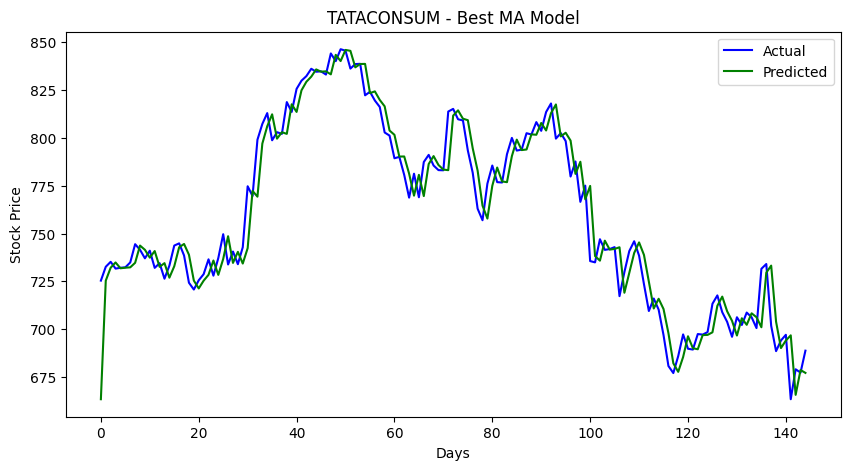

In [7]:
# Best model
model = ARIMA(data1, order=(1,1,2))

model_fit = model.fit()

# Predict test data
y_pred = model_fit.predict(
    start=0,
    end=len(data1)-1
)

# Convert normalized values to original prices
y_pred_original = Ms.inverse_transform(
    np.array(y_pred).reshape(-1,1)
)

Y_test_original = Ms.inverse_transform(
    np.array(data1).reshape(-1,1)
)
rmse, mape =rmsemape(Y_test_original,y_pred_original)

# Plot
from stockFunctions import graph

graph(
    Y_test_original,
    y_pred_original,
    "Actual",
    "Predicted",
    "TATACONSUM - Best MA Model",
    "Days",
    "Stock Price"
)

In [8]:
# Forecast four future values
forecast = model_fit.predict(len(data1), len(data1)+4)

# Convert forecast values back to original stock prices
forecast_original = Ms.inverse_transform(
    np.array(forecast).reshape(-1, 1)
)

# Get the last date from original dataset
last_date = skt_data.index.max()

# Generate next four business days
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),#time delta mean how many day to add to the last date ex. 7th Jan then it wll 8th Jan next
    periods=5,# based on the days in the forecast variable
    freq='D'#(B=Mon-Fri, D=Including weekend)
)

# Combine dates and predicted prices
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted Stock Price': forecast_original[:,0] # we can use flatten as well
})

print(forecast_df)

        Date  Predicted Stock Price
0 2022-01-29             687.995394
1 2022-01-30             687.799861
2 2022-01-31             687.806698
3 2022-02-01             687.806459
4 2022-02-02             687.806467


In [10]:
forecast_df.to_csv("Close_KB_ARiMA.csv",index=False)

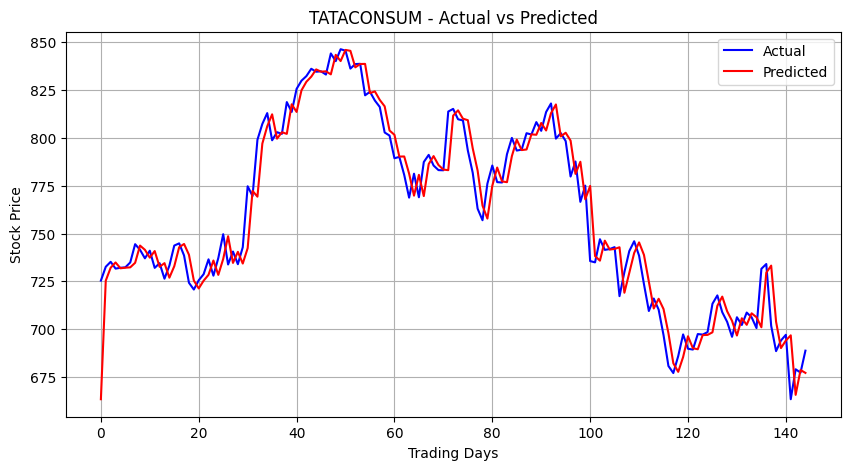

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(Y_test_original.flatten(), color='blue', label='Actual')
plt.plot(y_pred_original.flatten(), color='red', label='Predicted')

plt.title('TATACONSUM - Actual vs Predicted')
plt.xlabel('Trading Days')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)

plt.show()